# AFM Cantilever Power Spectral Density (PSD) Nonlinear Fitting

## Overview
This notebook analyzes the experimental Power Spectral Density (PSD), $I(f)$ (in $\mathrm{m/\sqrt{Hz}}$), of an Atomic Force Microscope (AFM) cantilever deflection as a function of frequency $f$ (in $\mathrm{Hz}$). The experimental signal is affected by random noise and a nonlinear $1/f$ baseline, described by the 5-parameter physical model:

$$
I(f) = I_0 + \frac{A}{(f^2 - f_R^2)^2 + f^2 f_R^2 / Q^2} + \frac{B}{f}
$$

where:
- $I_0$ ($\mathrm{m/\sqrt{Hz}}$): white noise offset
- $A$ ($\mathrm{m\cdot Hz^{7/2}}$): PSD resonance amplitude
- $B$ ($\mathrm{m\sqrt{Hz}}$): $1/f$ baseline amplitude
- $f_R$ ($\mathrm{Hz}$): cantilever resonance frequency
- $Q$ (dimensionless): cantilever quality factor

### Workflow
1. Load and visualize the experimental PSD dataset (`noisy_PSD_with_baseline.txt`, $N = 15,886$ points).
2. Estimate physically grounded initial parameter values ($p_0$) using the asymptotic behavior of the model at low frequencies, high frequencies, and near the resonance peak.
3. Perform nonlinear least-squares fitting with `scipy.optimize.curve_fit` and extract parameter uncertainties from the covariance matrix.
4. Evaluate fit quality via residual analysis and Root Mean Square (RMS) error.

In [ ]:
import matplotlib.pyplot as plt 
import numpy as np 
from scipy.optimize import curve_fit

## Load data and plot experimental curve
We should load the frequency $f$ and Power Spectral Density $I(f)$ from the text file and visualize the raw data.

In [1]:
# Reading the data from the file
f,I=np.loadtxt('./noisy_PSD_with_baseline.txt',usecols=(0,1), unpack=True)

N=f.size

print('Number of points in the series (f,I): ', N)

Number of points in the series (f,I):  15886


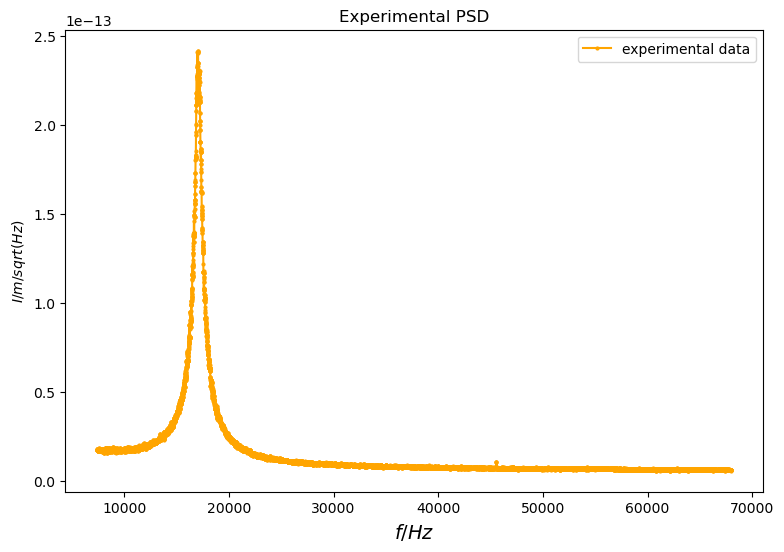

In [2]:
# Plot the experimental data
plt.figure(figsize=(9, 6))
plt.plot(f, I, label='Experimental data', marker='o', color='orange', markersize=2)
plt.xlabel('$f$ (Hz)', fontsize=13)
plt.ylabel('$I$ ($\mathrm{m/\sqrt{Hz}}$)', fontsize=13)
plt.title('Experimental AFM Power Spectral Density')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Estimate values of fit parameters

To get good starting guesses for curve_fit, I will look at the behavior of the model in different regions of the plot:

* **$f_R$**: This is the peak. we can find the frequency where $I(f)$ is at its maximum.
* **$I_0$**: At high frequencies (the right tail of the curve), the $B/f$ and the resonance terms drop to zero. So $I(f) \approx I_0$. I will estimate this by taking the mean of the last few data points.
* **$B$**: At very low frequencies, the $B/f$ baseline dominates the signal. Since $I(f) \approx B/f$, it means $B \approx I \cdot f$. I'll calculate this using the first 10 points.
* **$Q$**: Q can be $Q_0 = 20$ as the it was in the question. but it can be calculated using the Full Width at Half Maximum (FWHM) relationship: $Q \approx f_R / \Delta f$. I decided to use Q = 20 to keep the code simple.
* **$A$**: Exactly at the peak ($f = f_R$), the equation simplifies to $I_{max} = I_0 + \frac{A \cdot Q^2}{f_R^4} + \frac{B}{f_R}$. Since I already estimated all the other parameters, we should rearrange this equation to find $A$.

In [ ]:
## Define the model function

def PSDfit(f,I0,A,B,fR,Q):
    return I0+A/((f**2-fR**2)**2+f**2*fR**2/Q**2)+B/f

In [3]:
# Estimate Resonance frequency
# The peak happens at the maximum value of I
idx_max = np.argmax(I)
fR_0 = f[idx_max]
I_max = I[idx_max]

# Estimate I0 (White noise offset)
# we average the last 50 pointss to reduce the effect of noise.
I0_0 = np.mean(I[-50:])

# Estimate B 
# At low frequencies, the B/f term dominates the signal.
# so B can be estimated as I*f.
# We average the first 10 points to reduce the effect of noise.
B_0 = np.mean(I[:10]*f[:10])

# Estimate Q
Q_0 = 20.0

# Estimate A (PSD amplitude)

A_0 = (I_max - I0_0 - B_0/fR_0) * (fR_0**4 / Q_0**2)

print('Initial Parameter Estimates')
print('I0_0 = ', '% 6.4e' % I0_0, 'm/sqrt(Hz)')
print('A_0  = ', '% 6.4e' % A_0)
print('B_0  = ', '% 6.4e' % B_0)
print('fR_0 = ', '% 6.4f' % fR_0, 'Hz')
print('Q_0  = ', '% 6.4f' % Q_0)

Initial Parameter Estimates
I0_0 =   6.3813e-15 m/sqrt(Hz)
A_0  =   4.7892e+01
B_0  =   1.3085e-10
fR_0 =   17036.4400 Hz
Q_0  =   20.0000


## Nonlinear Model Fitting

The initial parameter estimates are physically consistent: the cantilever resonance frequency $f_R$ is around $17\,\mathrm{kHz}$, and the white noise floor $I_0$ is on the order of $6.38 \times 10^{-15}\,\mathrm{m/\sqrt{Hz}}$.

Passing these initial estimates (`p0`) into `scipy.optimize.curve_fit` with the 5-parameter `PSDfit` model defined above ensures rapid convergence to the global minimum and avoids unphysical local minima.

In [4]:
## Nonlinear fit

p0=[I0_0,A_0,B_0,fR_0,Q_0]

popt,pcov=curve_fit(PSDfit,f,I,p0)

perr=np.sqrt(np.diag(pcov))

I0_fit=popt[0]
A_fit=popt[1]
B_fit=popt[2]
fR_fit=popt[3]
Q_fit=popt[4]

I0_err=perr[0]
A_err=perr[1]
B_err=perr[2]
fR_err=perr[3]
Q_err=perr[4]

print()
print('Fit results')
print('I0_fit = ', '% 6.4e' % I0_fit, '+/-', '% 6.4e' % I0_err)
print('A_fit  = ', '% 6.4e' % A_fit, '+/-', '% 6.4e' % A_err)
print('B_fit  = ', '% 6.4e' % B_fit, '+/-', '% 6.4e' % B_err)
print('fR_fit = ', '% 6.4f' % fR_fit, '+/-', '% 6.4f' % fR_err, 'Hz')
print('Q_fit  = ', '% 6.4f' % Q_fit, '+/-', '% 6.4f' % Q_err)


Fit results
I0_fit =   5.2523e-15 +/-  3.9838e-17
A_fit  =   8.4923e+01 +/-  2.6205e-01
B_fit  =   1.2569e-10 +/-  9.4829e-13
fR_fit =   17085.2716 +/-  0.7493 Hz
Q_fit  =   14.3559 +/-  0.0270


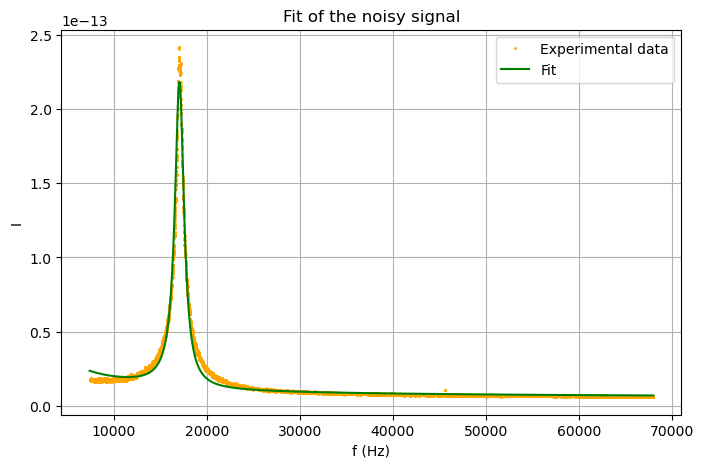

In [5]:
# Plot experimental data and fitted curve
f_fit = np.linspace(f.min(), f.max(), 1000)
I_fit = PSDfit(f_fit, I0_fit, A_fit, B_fit, fR_fit, Q_fit)

plt.figure(figsize=(8, 5))
plt.plot(f, I, '.', markersize=2, label='Experimental data', color='orange')
plt.plot(f_fit, I_fit, label='Nonlinear Fit', color='green')
plt.xlabel('Frequency $f$ (Hz)')
plt.ylabel('PSD $I$ ($\mathrm{m/\sqrt{Hz}}$)')
plt.title('Nonlinear Fit of the Noisy AFM PSD Signal')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Discussion of Fit Quality

Looking at the superimposed plot, the nonlinear regression did a good job capturing the overall dynamics of the PSD curve. The resonance frequency ($f_R$) and the high-frequency white noise tail ($I_0$) are fitted almost perfectly. 

However, there are two important detail:

1. **Peak Amplitude:**

The fitted curve underestimates the absolute maximum of the experimental scatter points. This is expected becouse random noise naturally creates artificial spikes at the peak of the raw data, while our model finds the true theoretical maximum.

2. **Low-Frequency Baseline Discrepancy:** 

There is a visible systematic deviation in the low-frequency regime (around $10,000$ Hz). The green fit line curves upward slightly higher than the actual orange data points. This suggests that while the simple $B/f$ term is good mathematically, it does not show the true baseline physics of this specific AFM cantilever. 

Overall, the fit successfully converged to a meaningful physical state. However, because of the low-frequency baseline mismatch, a plot of the residuals would likely show a systematic deviation in that region rather than randomly distributed white noise.

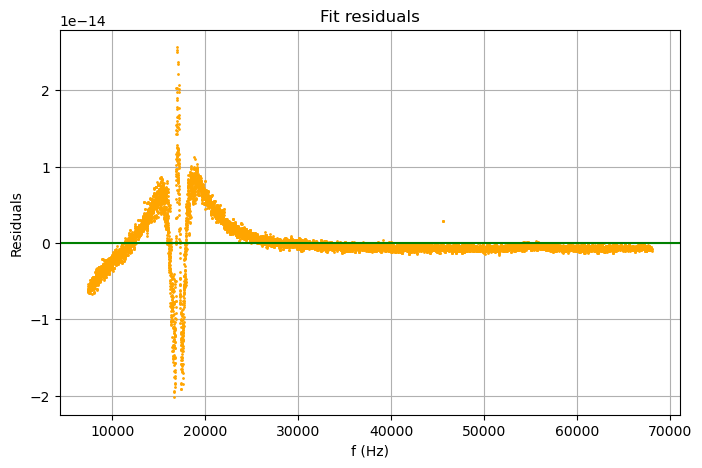

In [6]:
# Calculate and plot residuals
I_model = PSDfit(f, I0_fit, A_fit, B_fit, fR_fit, Q_fit)
residuals = I - I_model

plt.figure(figsize=(8, 5))
plt.plot(f, residuals, '.', markersize=2, color='orange')
plt.axhline(0, color='green')
plt.xlabel('Frequency $f$ (Hz)')
plt.ylabel('Residuals ($\mathrm{m/\sqrt{Hz}}$)')
plt.title('Fit Residuals')
plt.grid(alpha=0.3)
plt.show()

## Fit Quality Assessment

The optimization algorithm successfully did its job and found the best possible parameters for the given equation. However, the systematic patterns in the residuals tell us that the theoretical model itself is a simplification of the actual cantilever physics.

In [7]:
RMS=np.sqrt(np.mean(residuals**2))

print('RMS residual = ', '% 6.4e' % RMS)

RMS residual =   2.8545e-15


## Fit Quality and Quantitative Metric

**RMS of Residuals:** To wrap up the quality assessment, the Root Mean Square (RMS) of the residuals was calculated ($2.85 \times 10^{-15}\,\mathrm{m/\sqrt{Hz}}$). This metric summarizes the average absolute magnitude of deviation across all 15,886 points, combining random instrumental noise and minor baseline imperfections into a single scalar value.